<a href="https://colab.research.google.com/github/sabrina-cortes/Metodos-Numericos-FIS1344-TAREAS/blob/main/Tarea_9_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Tarea 9.8: Método de Múltiples Pasos

Enunciado:
Use el método de Adams-Moulton de tres pasos descrito en clase para resolver el siguiente problema de valor inicial:

$$
y'(t)=te^{3t}-2y,
\qquad
0\leq t\leq1,
\qquad
y(0)=0.
$$

Recuerde que este método usa $w_{i+1}$ para calcular $w_{i+1}$ tal que es necesario resolver algebráicamente la ecuación resultante y así obtener una expresión explícita para $w_{i+1}$  que se pueda usar en el código.


El método de Adams-Moulton de tres pasos es

$$
w_{i+1}
=
w_i+
\frac{h}{24}
\left[
9f(t_{i+1},w_{i+1})
+19f(t_i,w_i)
-5f(t_{i-1},w_{i-1})
+f(t_{i-2},w_{i-2})
\right].
$$

Para este problema,

$$
f(t,y)=te^{3t}-2y,
$$

por lo que

$$
f(t_{i+1},w_{i+1})
=
t_{i+1}e^{3t_{i+1}}-2w_{i+1}.
$$

Reemplazando:

$$
w_{i+1}
=
w_i+
\frac{h}{24}
\left[
9t_{i+1}e^{3t_{i+1}}
-18w_{i+1}
+19f_i
-5f_{i-1}
+f_{i-2}
\right].
$$

Separando el término que contiene $w_{i+1}$:

$$
w_{i+1}
+
\frac{18h}{24}w_{i+1}
=
w_i+
\frac{h}{24}
\left[
9t_{i+1}e^{3t_{i+1}}
+19f_i
-5f_{i-1}
+f_{i-2}
\right].
$$

Como

$$
\frac{18}{24}=\frac34,
$$

se obtiene

$$
w_{i+1}
\left(
1+\frac{3h}{4}
\right)
=
w_i+
\frac{h}{24}
\left[
9t_{i+1}e^{3t_{i+1}}
+19f_i
-5f_{i-1}
+f_{i-2}
\right].
$$

Finalmente,

$$
{
w_{i+1}
=
\frac{
w_i+
\frac{h}{24}
\left[
9t_{i+1}e^{3t_{i+1}}
+19f_i
-5f_{i-1}
+f_{i-2}
\right]
}{
1+\frac{3h}{4}
}
}
$$

In [16]:
import numpy as np
import matplotlib.pyplot as plt

In [17]:
def f(t, y):
    return t*np.exp(3*t) - 2*y

In [18]:
def rk4_step(f, t, w, h):

    k1 = h*f(t, w)
    k2 = h*f(t + h/2, w + k1/2)
    k3 = h*f(t + h/2, w + k2/2)
    k4 = h*f(t + h, w + k3)

    return (k1 + 2*k2 + 2*k3 + k4)/6

In [19]:
def am3(f, a, b, yo, N):

    h = (b-a)/N

    ts = np.zeros(N+1)
    ws = np.zeros(N+1)

    ts[0] = a
    ws[0] = yo

    #Primeros dos pasos con RK4
    for i in range(2):
        ts[i+1] = ts[i] + h
        ws[i+1] = ws[i] + rk4_step(f, ts[i], ws[i], h)

    #Adams-Moulton
    for i in range(2, N):

        ti1 = ts[i] + h

        fi = f(ts[i], ws[i])
        fim1 = f(ts[i-1], ws[i-1])
        fim2 = f(ts[i-2], ws[i-2])

        numerador = ws[i] + h/24 * (
            9*ti1*np.exp(3*ti1)
            + 19*fi
            - 5*fim1
            + fim2
        )

        ws[i+1] = numerador / (1 + 3*h/4)
        ts[i+1] = ti1

    return ts, ws

Para probar el método podemos utilizar, por ejemplo $N=10$, por lo tanto tendremos que $h=0.1$

In [20]:
ts, ws = am3(f, 0, 1, 0, 10)

for t, w in zip(ts, ws):
    print(t, w)

def exacta(t):
    return np.exp(3*t)*(t/5 - 1/25) + np.exp(-2*t)/25

0.0 0.0
0.1 0.00575463131152366
0.2 0.026818770596771152
0.30000000000000004 0.07118212562590197
0.4 0.1508546261844579
0.5 0.2837454524301849
0.6 0.4962191975403319
0.7 0.826777902371369
0.7999999999999999 1.3312894157723214
0.8999999999999999 2.090395753319865
0.9999999999999999 3.219985033890847


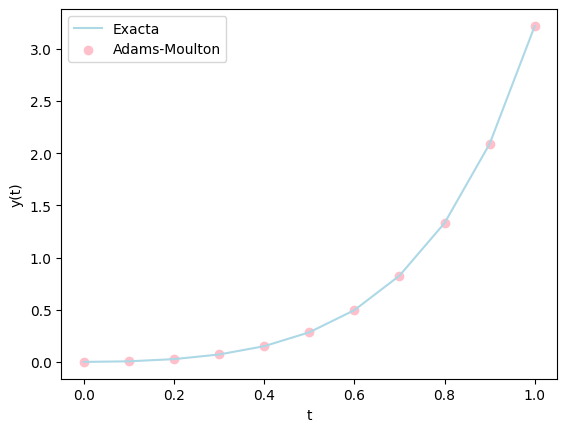

In [21]:
plt.plot(ts, exacta(ts), color='lightblue' ,label="Exacta")
plt.scatter(ts, ws, color='pink' ,label="Adams-Moulton")

plt.xlabel("t")
plt.ylabel("y(t)")
plt.legend()
plt.show()